IMPORT STATEMENTS

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


UPLOADING THE DATASET


In [120]:
df= pd.read_csv("/content/manufacturing_sensors_regression.csv")
df.head()

,temp_c,rpm_dup,maintenance_required,vibration,rpm,operator_shift,pressure,sensor_id,machine_age_days
0,54.63,2256.0,0.0,0.224,2256.0,C,24.10,SEN1000,4488.0
1,60.4,2844.0,0.0,0.319,2844.0,A,26.05,SEN1001,355.0
2,66.68,3751.0,0.0,0.338,3751.0,A,28.79,SEN1002,1878.0
3,58.8,1000.0,0.0,0.320,1000.0,C,27.36,SEN1003,4860.0
4,66.27,4576.0,0.0,0.482,4576.0,B,33.88,SEN1004,4460.0


In [121]:
df.info()
df.duplicated()
df.drop_duplicates()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   temp_c                244 non-null    object 
 1   rpm_dup               239 non-null    float64
 2   maintenance_required  237 non-null    float64
 3   vibration             245 non-null    float64
 4   rpm                   239 non-null    float64
 5   operator_shift        243 non-null    object 
 6   pressure              237 non-null    float64
 7   sensor_id             238 non-null    object 
 8   machine_age_days      245 non-null    float64
dtypes: float64(6), object(3)
memory usage: 18.2+ KB


,temp_c,rpm_dup,maintenance_required,vibration,rpm,operator_shift,pressure,sensor_id,machine_age_days
0,54.63,2256.0,0.0,0.224,2256.0,C,24.10,SEN1000,4488.0
1,60.4,2844.0,0.0,0.319,2844.0,A,26.05,SEN1001,355.0
2,66.68,3751.0,0.0,0.338,3751.0,A,28.79,SEN1002,1878.0
3,58.8,1000.0,0.0,0.320,1000.0,C,27.36,SEN1003,4860.0
4,66.27,4576.0,0.0,0.482,4576.0,B,33.88,SEN1004,4460.0
...,...,...,...,...,...,...,...,...,...
245,58.19,2261.0,0.0,0.705,2261.0,A,30.76,SEN1245,936.0
246,65.11,2160.0,0.0,0.650,2160.0,A,32.45,NaN,3549.0
247,55.28,2186.0,0.0,0.388,2186.0,B,30.84,SEN1247,4650.0
248,57.87,3886.0,0.0,0.218,3886.0,C,32.13,SEN1248,2166.0


In [122]:
df.isnull().sum()

,0
temp_c,13
rpm_dup,18
maintenance_required,20
vibration,12
rpm,18
operator_shift,14
pressure,20
sensor_id,19
machine_age_days,12


In [123]:
df["operator_shift"].fillna(df["operator_shift"].mode()[0],inplace = True)
df["maintenance_required"] = df["maintenance_required"].mode()[0]
df["temp_c"].fillna(df["temp_c"].mode()[0],inplace = True)
df.isnull().sum()

/tmp/ipykernel_1311/3687605298.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["operator_shift"].fillna(df["operator_shift"].mode()[0],inplace = True)
/tmp/ipykernel_1311/3687605298.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(v

,0
temp_c,0
rpm_dup,18
maintenance_required,0
vibration,12
rpm,18
operator_shift,0
pressure,20
sensor_id,19
machine_age_days,12


In [124]:
df["temp_c"] = pd.to_numeric(df["temp_c"],errors = "coerce")
df["temp_c"].isnull().sum()
df.loc[df["temp_c"] == 3236, "temp_c"]=np.nan

In [125]:
df["sensor_id"] = df["sensor_id"].str.strip().str.upper()
df["sensor_id"] = df["sensor_id"].fillna(df["sensor_id"].mode()[0])

In [126]:
df["temp_c"] = df["temp_c"].median()
df["rpm"] = df["rpm"].fillna(df["rpm"].median())
df["rpm_dup"] = df["rpm_dup"].fillna(df["rpm_dup"].median())
df["vibration"] = df["vibration"].fillna(df["vibration"].median())
df["pressure"] = df["pressure"].fillna(df["pressure"].median())
df["machine_age_days"] = df["machine_age_days"].fillna(df["machine_age_days"].median())
df.isnull().sum()

,0
temp_c,0
rpm_dup,0
maintenance_required,0
vibration,0
rpm,0
operator_shift,0
pressure,0
sensor_id,0
machine_age_days,0


PIE CHART

([<matplotlib.patches.Wedge at 0x7e63ea3ed450>,
 [Text(0.4131751534030514, 1.0194539188263319, 'A'),
  Text(-1.0734790959463922, -0.24008879725242616, 'B'),
  Text(0.6257220046385029, -0.9046944085773789, 'C')],
 [Text(0.22536826549257347, 0.5560657739052719, '37.7%'),
  Text(-0.5855340523343957, -0.13095752577405062, '31.5%'),
  Text(0.3413029116210015, -0.493469677405843, '30.7%')])

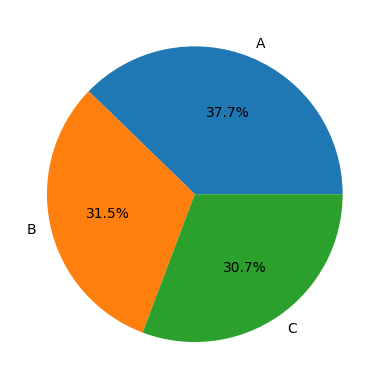

In [127]:
shift_count = df["operator_shift"].value_counts()
plt.pie(shift_count.values, labels = shift_count.index, autopct ="%0.1f%%" )

HISTOGRAM



<Axes: xlabel='pressure', ylabel='Count'>

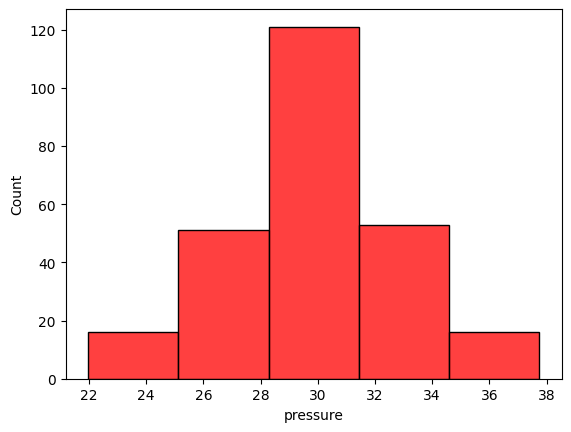

In [128]:
sns.histplot(df["pressure"],bins = 5 , color = "red")

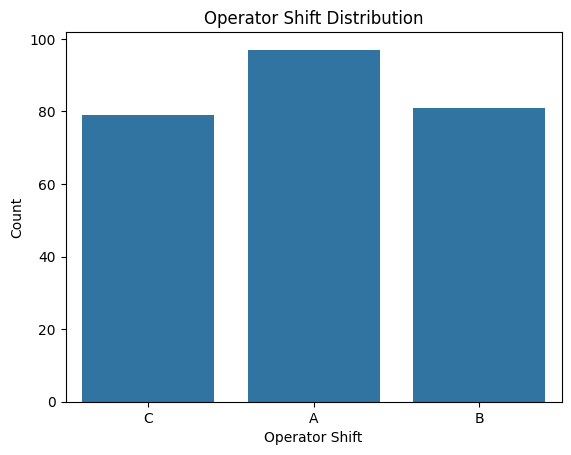

In [129]:
sns.countplot(data = df, x = "operator_shift")
plt.title("Operator Shift Distribution")
plt.xlabel("Operator Shift")
plt.ylabel("Count")
plt.show()

Text(0.5, 1.0, 'Histogram of pressure')

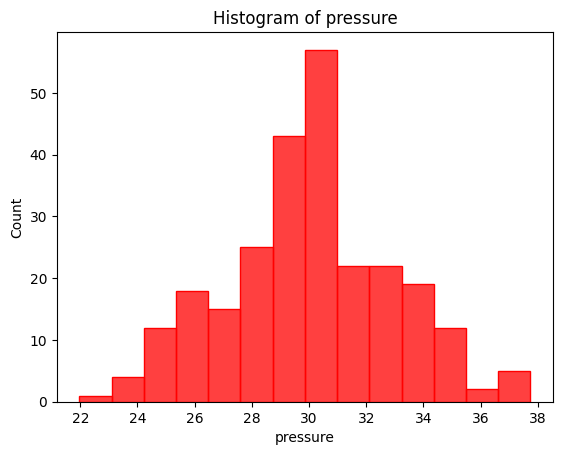

In [130]:
sns.histplot(data = df, x = "pressure", color = "red", edgecolor = "red")
plt.title("Histogram of pressure")

<Axes: xlabel='vibration'>

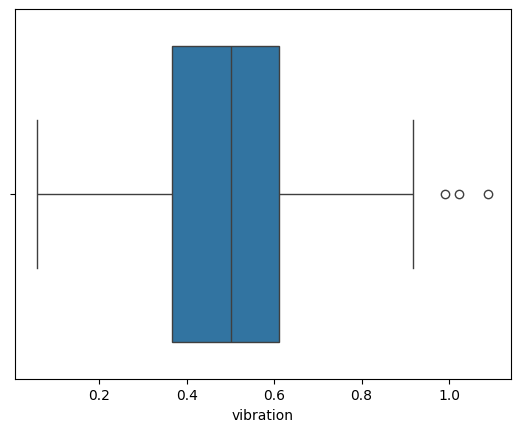

In [131]:
sns.boxplot(x = df["vibration"])

<Axes: xlabel='pressure', ylabel='rpm'>

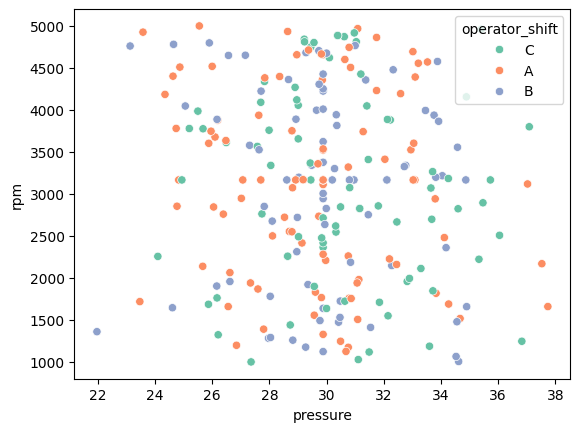

In [132]:
sns.scatterplot(data = df, x = "pressure", y = "rpm", hue = "operator_shift",palette = "Set2")


<Axes: xlabel='operator_shift', ylabel='count'>

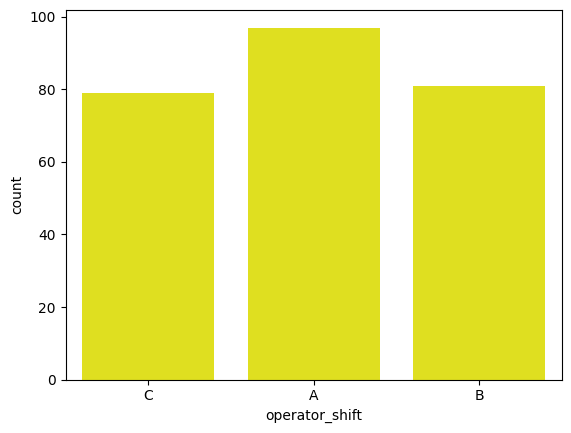

In [133]:
sns.countplot(x = "operator_shift", data = df, color ="yellow" )

<Axes: >

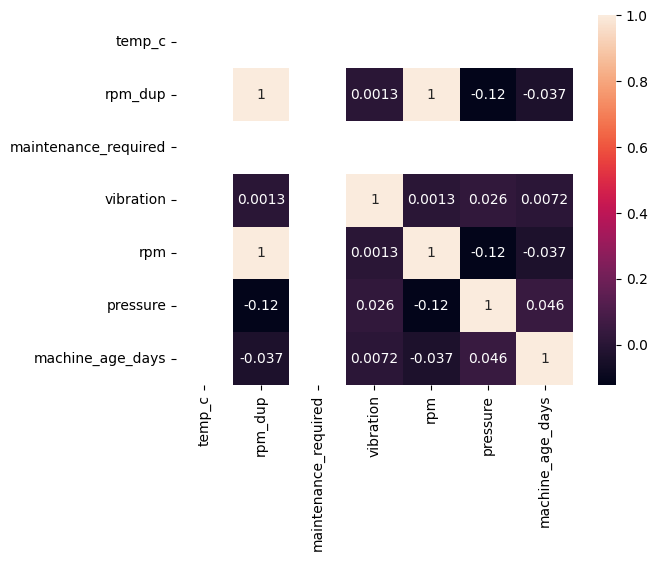

In [134]:
sns.heatmap(df.corr(numeric_only = True), annot = True)

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been as

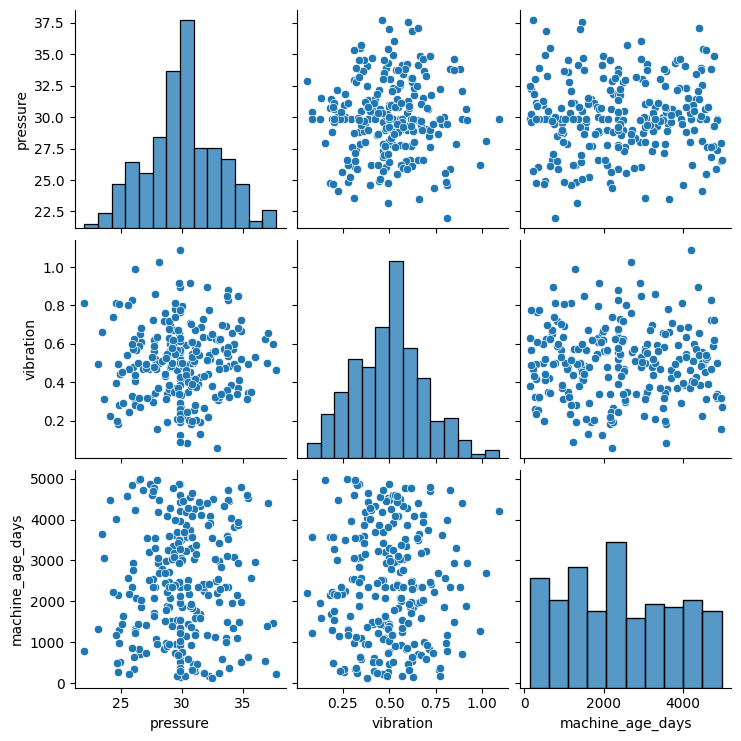

In [135]:
sns.pairplot(data = df, vars=["pressure","vibration","machine_age_days"],palette = "Set2")


/tmp/ipykernel_1311/2545867606.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = df, x = "pressure", y = "vibration", size = "rpm",sizes = (20, 300), alpha = 0.6,palette = "Set2")


<Axes: xlabel='pressure', ylabel='vibration'>

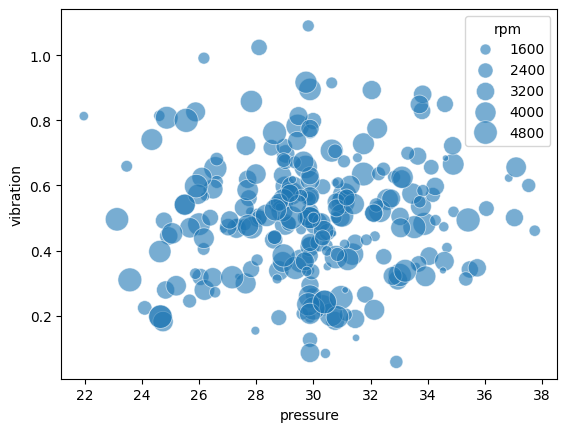

In [137]:
sns.scatterplot(data = df, x = "pressure", y = "vibration", size = "rpm",sizes = (20, 300), alpha = 0.6,palette = "Set2")
